
# Homework: Cybersecurity Alert Severity Prediction with BERT Embeddings, PCA, and Regression

## Course context
In this homework, you will use machine learning to support **cybersecurity alert triage**. Security teams often receive many alerts, and they need to decide which alerts are more severe and should be investigated first.

You will use short cybersecurity alert descriptions, convert them into **BERT embeddings**, visualize the alerts using **PCA**, and train regression models to predict alert severity.

## What you will practice
By completing this homework, you will practice how to:

1. Represent text using pretrained BERT embeddings.
2. Combine text embeddings with structured cybersecurity features.
3. Use PCA to reduce high-dimensional embeddings to two dimensions.
4. Train regression models to predict severity scores.
5. Evaluate regression models using MAE, RMSE, and R².
6. Interpret model errors in a cybersecurity decision-making context.

## Submission
Submit your completed `.ipynb` notebook. Make sure all code cells run successfully from top to bottom before submitting.



## Important note about BERT

This notebook uses the Hugging Face `transformers` library and the pretrained model `bert-base-uncased`.

The first time you run this notebook, Python may need to download the BERT model. This can take a few minutes. Google Colab is recommended if your local computer does not have the required packages installed.


In [1]:

# If you are using Google Colab, run this cell first.
# If these packages are already installed, you can skip this cell.

!pip install -q transformers torch scikit-learn pandas matplotlib


## 1. Import libraries

In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from transformers import BertTokenizer, BertModel

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

np.random.seed(42)



## 2. Create a synthetic cybersecurity alert dataset

The dataset below is synthetic. Each row represents a security alert.

The target variable is `severity_score`, which ranges from 0 to 100.

Higher scores indicate alerts that should receive more urgent attention.


In [3]:

alerts = [
    ("Repeated failed login attempts detected for employee account from normal office location.", "credential_access", 12, 0, 0, 0, 0, 2, 35),
    ("Multiple failed logins followed by successful access from an unfamiliar country.", "credential_access", 37, 1, 0, 0, 0, 3, 68),
    ("User account locked after repeated password guessing attempts.", "credential_access", 24, 0, 0, 0, 0, 2, 44),
    ("Privileged administrator account experienced repeated login failures from foreign IP address.", "credential_access", 51, 1, 1, 0, 0, 5, 86),
    ("Suspicious login from new device during unusual nighttime hours.", "credential_access", 9, 1, 0, 0, 0, 3, 58),
    ("Credential stuffing pattern observed across several customer-facing accounts.", "credential_access", 63, 1, 0, 0, 0, 4, 75),
    ("Password spray activity detected against cloud email accounts.", "credential_access", 48, 1, 0, 0, 0, 4, 72),
    ("Normal password reset request completed by verified user.", "credential_access", 1, 0, 0, 0, 0, 1, 12),

    ("Endpoint antivirus detected known malware on a workstation.", "malware", 0, 0, 0, 0, 1, 3, 64),
    ("Malware quarantined successfully with no evidence of lateral movement.", "malware", 0, 0, 0, 0, 1, 2, 49),
    ("Ransomware-like file encryption behavior detected on shared drive.", "malware", 0, 0, 1, 1, 1, 5, 95),
    ("Suspicious executable launched from temporary folder.", "malware", 0, 0, 0, 0, 1, 3, 60),
    ("Trojan downloader contacted command-and-control domain.", "malware", 0, 1, 0, 0, 1, 4, 88),
    ("Potential adware detected on low-risk training laptop.", "malware", 0, 0, 0, 0, 1, 1, 32),
    ("Malicious PowerShell command attempted to disable endpoint protection.", "malware", 0, 0, 1, 0, 1, 5, 91),
    ("Blocked malware attachment found in inbound email before user opened it.", "malware", 0, 0, 0, 0, 1, 2, 41),

    ("Large outbound data transfer observed from finance database server.", "data_exfiltration", 0, 0, 0, 1, 0, 5, 90),
    ("Unusual upload of customer records to personal cloud storage service.", "data_exfiltration", 0, 1, 0, 1, 0, 5, 94),
    ("Employee downloaded unusually large number of files from internal repository.", "data_exfiltration", 0, 0, 0, 1, 0, 4, 72),
    ("Data export from HR system occurred outside normal business hours.", "data_exfiltration", 0, 1, 0, 1, 0, 5, 89),
    ("Small file transfer to approved vendor endpoint.", "data_exfiltration", 0, 0, 0, 0, 0, 2, 22),
    ("Sensitive spreadsheet emailed to external personal email address.", "data_exfiltration", 0, 0, 0, 1, 0, 4, 78),
    ("Potential database dump generated by service account.", "data_exfiltration", 0, 0, 1, 1, 0, 5, 96),
    ("Encrypted archive uploaded to unknown external server.", "data_exfiltration", 0, 1, 0, 1, 0, 4, 87),

    ("User attempted to access restricted payroll dashboard without permission.", "privilege_misuse", 3, 0, 0, 0, 0, 4, 52),
    ("Standard user added themselves to a privileged security group.", "privilege_misuse", 0, 0, 1, 0, 0, 5, 92),
    ("Administrative role assigned to user outside normal change management process.", "privilege_misuse", 0, 0, 1, 0, 0, 5, 84),
    ("Service account created new administrator account.", "privilege_misuse", 0, 0, 1, 0, 0, 5, 93),
    ("User accessed shared folder allowed by department policy.", "privilege_misuse", 0, 0, 0, 0, 0, 1, 15),
    ("Privileged command executed on production server without approved ticket.", "privilege_misuse", 0, 0, 1, 0, 0, 5, 82),
    ("Suspicious change to firewall rule made by administrator account.", "privilege_misuse", 0, 0, 1, 0, 0, 5, 80),
    ("Developer requested temporary elevated permissions through approved process.", "privilege_misuse", 0, 0, 0, 0, 0, 2, 20),

    ("Phishing email reported by user and blocked by email gateway.", "phishing", 0, 0, 0, 0, 0, 2, 28),
    ("Employee clicked phishing link and entered credentials on fake login page.", "phishing", 0, 1, 0, 0, 0, 4, 79),
    ("Suspicious email contained invoice attachment from unknown sender.", "phishing", 0, 0, 0, 0, 0, 2, 40),
    ("Multiple employees received targeted spear phishing message impersonating executive.", "phishing", 0, 1, 0, 0, 0, 4, 73),
    ("Credential harvesting page detected after phishing campaign.", "phishing", 18, 1, 0, 0, 0, 4, 76),
    ("Email security system blocked bulk spam messages.", "phishing", 0, 0, 0, 0, 0, 1, 18),
    ("Phishing message requested urgent gift card purchase.", "phishing", 0, 0, 0, 0, 0, 1, 24),
    ("User reported suspicious email before interacting with links or attachments.", "phishing", 0, 0, 0, 0, 0, 1, 16),

    ("Web server received high number of requests from a single IP address.", "network_attack", 0, 1, 0, 0, 0, 3, 55),
    ("Possible denial-of-service attack against public application.", "network_attack", 0, 1, 0, 0, 0, 4, 70),
    ("Port scanning activity detected against internal subnet.", "network_attack", 0, 0, 0, 0, 0, 3, 45),
    ("Firewall blocked repeated connection attempts from known malicious IP.", "network_attack", 0, 1, 0, 0, 0, 3, 50),
    ("Suspicious lateral movement observed between internal hosts.", "network_attack", 0, 0, 1, 0, 0, 5, 89),
    ("Routine vulnerability scan launched by approved internal scanner.", "network_attack", 0, 0, 0, 0, 0, 2, 14),
    ("Unusual outbound beaconing pattern detected from workstation.", "network_attack", 0, 1, 0, 0, 1, 4, 83),
    ("Unexpected remote desktop connection attempt from external address.", "network_attack", 5, 1, 0, 0, 0, 4, 67),

    ("Cloud storage bucket accidentally configured for public access.", "misconfiguration", 0, 0, 0, 1, 0, 4, 81),
    ("Database backup stored without encryption in internal location.", "misconfiguration", 0, 0, 0, 0, 0, 4, 57),
    ("Server missing critical security patch for known vulnerability.", "misconfiguration", 0, 0, 0, 0, 0, 4, 62),
    ("Low-risk workstation missing optional software update.", "misconfiguration", 0, 0, 0, 0, 0, 1, 21),
    ("Exposed API key found in internal code repository.", "misconfiguration", 0, 0, 0, 1, 0, 4, 85),
    ("Overly permissive access policy applied to development environment.", "misconfiguration", 0, 0, 1, 0, 0, 3, 66),
    ("Unused test account remains active after project closure.", "misconfiguration", 0, 0, 0, 0, 0, 2, 34),
    ("Logging disabled on critical authentication service.", "misconfiguration", 0, 0, 0, 0, 0, 5, 77),
]

df = pd.DataFrame(alerts, columns=[
    "alert_text",
    "alert_type",
    "failed_login_count",
    "unusual_geo",
    "privilege_escalation",
    "data_exfiltration",
    "malware_detected",
    "asset_criticality",
    "severity_score"
])

df.head()


,alert_text,alert_type,failed_login_count,unusual_geo,privilege_escalation,data_exfiltration,malware_detected,asset_criticality,severity_score
0,Repeated failed login attempts detected for em...,credential_access,12,0,0,0,0,2,35
1,Multiple failed logins followed by successful ...,credential_access,37,1,0,0,0,3,68
2,User account locked after repeated password gu...,credential_access,24,0,0,0,0,2,44
3,Privileged administrator account experienced r...,credential_access,51,1,1,0,0,5,86
4,Suspicious login from new device during unusua...,credential_access,9,1,0,0,0,3,58


## 3. Inspect the dataset

In [5]:
# TODO 1:
# Display the shape of the dataset.
# Display summary statistics for numeric columns.
# Display the number of alerts in each alert_type.

# Your code here
print("Dataset Shape:", df.shape)

print("\nSummary Statistics for Numeric Columns:")
print(df.describe())

print("\nNumber of Alerts in each alert_type:")
print(df["alert_type"].value_counts())

Dataset Shape: (56, 9)

Summary Statistics for Numeric Columns:
       failed_login_count  unusual_geo  privilege_escalation  \
count           56.000000    56.000000             56.000000   
mean             4.839286     0.303571              0.196429   
std             13.545582     0.463961              0.400892   
min              0.000000     0.000000              0.000000   
25%              0.000000     0.000000              0.000000   
50%              0.000000     0.000000              0.000000   
75%              0.000000     1.000000              0.000000   
max             63.000000     1.000000              1.000000   

       data_exfiltration  malware_detected  asset_criticality  severity_score  
count          56.000000         56.000000          56.000000       56.000000  
mean            0.178571          0.160714           3.375000       61.178571  
std             0.386459          0.370591           1.369306       26.062936  
min             0.000000          0.000


### Question 1

Briefly answer the following:

1. What is the target variable? - severity_score

2. Which columns are structured numeric features?
failed_login_count
unusual_geo
privilege_escalation
data_exfiltration
malware_detected
asset_criticality

3. Which column contains unstructured text? - alert_text


4. Why might text descriptions be useful for predicting cybersecurity alert severity? - Text descriptions provide context and detail about the security event (e.g., tactics used, involved resources, specific actor behaviors) that structured columns (like binary flags or simple counts) cannot easily capture. Natural language processing of these descriptions allows a model to understand nuanced threats and accurately predict severity.


## 4. Load pretrained BERT

In [6]:

# Load the BERT tokenizer and model.
# This may take a few minutes the first time you run it.

model_name = "bert-base-uncased"

tokenizer = BertTokenizer.from_pretrained(model_name)
bert_model = BertModel.from_pretrained(model_name)

# Put BERT in evaluation mode because we are only using it to create embeddings.
bert_model.eval()


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (token_type_embeddings): Embedding(2, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-11): 12 x BertLayer(
        (attention): BertAttention(
          (self): BertSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
            (dropout): Dropout(p=0.1, inplace=False)
  


## 5. Create BERT embeddings - MEAN POOLINGS

BERT converts each alert description into a sequence of token embeddings.

For this assignment, we will use **mean pooling**: we average the token embeddings to create one vector for each alert description.

The output will be a matrix where:

- Each row represents one alert.
- Each column represents one dimension of the BERT embedding.


In [7]:

def get_bert_embeddings(texts, tokenizer, model, max_length=96, batch_size=8):
    """
    Convert a list of text strings into BERT embeddings using mean pooling.
    """
    all_embeddings = []

    for i in range(0, len(texts), batch_size):
        batch_texts = texts[i:i + batch_size]

        encoded = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=max_length,
            return_tensors="pt"
        )

        with torch.no_grad():
            outputs = model(**encoded)

        token_embeddings = outputs.last_hidden_state
        attention_mask = encoded["attention_mask"]

        # Expand the attention mask so it can be multiplied with token embeddings.
        input_mask_expanded = attention_mask.unsqueeze(-1).expand(token_embeddings.size()).float()

        # Sum token embeddings and divide by the number of non-padding tokens.
        sum_embeddings = torch.sum(token_embeddings * input_mask_expanded, dim=1)
        sum_mask = torch.clamp(input_mask_expanded.sum(dim=1), min=1e-9)
        mean_embeddings = sum_embeddings / sum_mask

        all_embeddings.append(mean_embeddings.cpu().numpy())

    return np.vstack(all_embeddings)


texts = df["alert_text"].tolist()

bert_embeddings = get_bert_embeddings(texts, tokenizer, bert_model)

print("BERT embedding matrix shape:", bert_embeddings.shape)


BERT embedding matrix shape: (56, 768)


## **Question 2**

1. **How many rows are in the BERT embedding matrix?**
   There are **56** rows (one for each cybersecurity alert in the dataset).

2. **How many columns are in the BERT embedding matrix?**
   There are **768** columns (corresponding to the hidden size of the standard `bert-base-uncased` model).

3. **What does one row represent?**
   One row represents the **768-dimensional mean-pooled dense vector representation (embedding)** of a single alert's description (`alert_text`).

4. **Why is the number of embedding columns much larger than the number of original dataset columns?**
   The original dataset columns represent a small, hand-selected set of simple structured attributes (e.g., category, numeric counts, and binary flags). In contrast, the BERT embedding columns represent the rich semantic dimensions of the unstructured natural language description. BERT maps each text string into a high-dimensional vector space (768 dimensions) to capture complex linguistic nuances, context, and semantic relationships that cannot be represented by a few simple, manual features.

## 6. Use PCA to visualize the BERT embeddings

In [8]:

pca = PCA(n_components=2)
bert_pca = pca.fit_transform(bert_embeddings)

df["pca_1"] = bert_pca[:, 0]
df["pca_2"] = bert_pca[:, 1]

print("Explained variance ratio:", pca.explained_variance_ratio_)
df[["alert_text", "alert_type", "severity_score", "pca_1", "pca_2"]].head()


Explained variance ratio: [0.11042616 0.10303818]


,alert_text,alert_type,severity_score,pca_1,pca_2
0,Repeated failed login attempts detected for em...,credential_access,35,-1.890716,-0.120551
1,Multiple failed logins followed by successful ...,credential_access,68,0.325455,0.325731
2,User account locked after repeated password gu...,credential_access,44,0.577152,1.117385
3,Privileged administrator account experienced r...,credential_access,86,1.069607,1.211334
4,Suspicious login from new device during unusua...,credential_access,58,-2.170413,0.236492


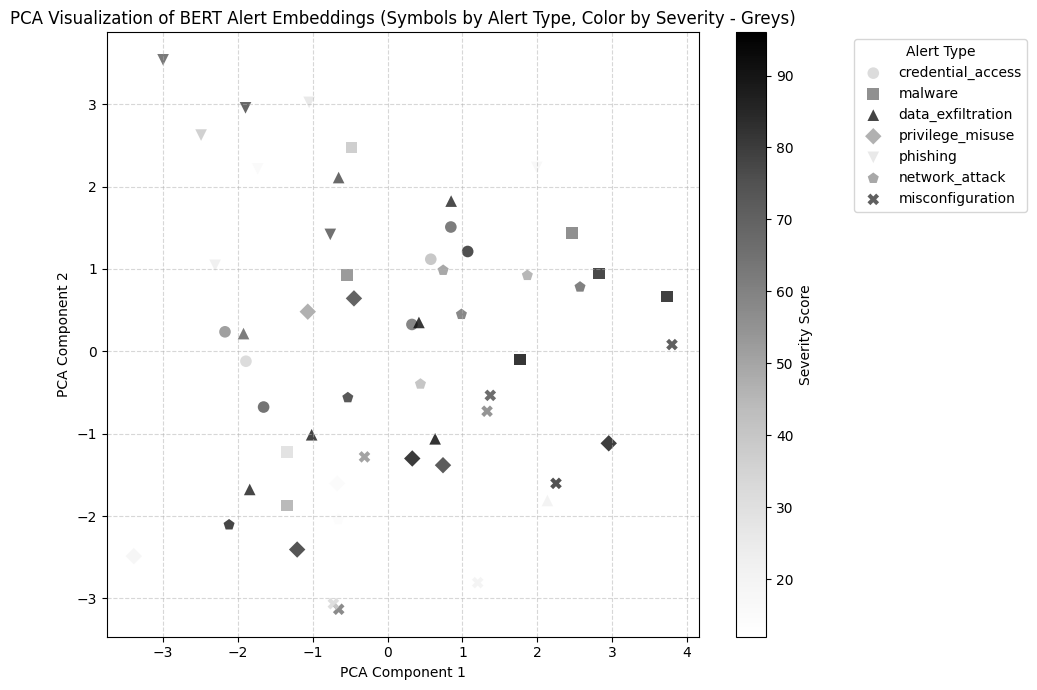

In [10]:
import matplotlib.pyplot as plt
import numpy as np

# Distinct markers for each alert type
markers = [
    "o", # Circle
    "s", # Square
    "^", # Triangle Up
    "D", # Diamond
    "v", # Triangle Down
    "p", # Pentagon
    "X", # Bold X
    "*"  # Star
]

plt.figure(figsize=(10, 7))

# We want a shared colorbar, so we need to set normalisation based on severity scores
min_sev, max_sev = df["severity_score"].min(), df["severity_score"].max()
sc = plt.scatter([], [],
                 c=[],
                 vmin=min_sev,
                 vmax=max_sev,
                 cmap="Greys"
                 )

# Loop over each unique alert type to plot them with their own marker
for i, alert_type in enumerate(df["alert_type"].unique()):
    subset = df[df["alert_type"] == alert_type]
    marker = markers[i % len(markers)]

    plt.scatter(
        subset["pca_1"],
        subset["pca_2"],
        c=subset["severity_score"],
        marker=marker,
        label=alert_type,
        vmin=min_sev,
        vmax=max_sev,
        cmap="Greys",
        alpha=0.8,
        s=70,
        edgecolors="none"
)

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("PCA Visualization of BERT Alert Embeddings (Symbols by Alert Type, Color by Severity - Greys)")

# Add legend for the symbols (alert types)
plt.legend(bbox_to_anchor=(1.25, 1), loc='upper left', title="Alert Type")

# Add colorbar for the severity scores
plt.colorbar(sc, label="Severity Score")
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

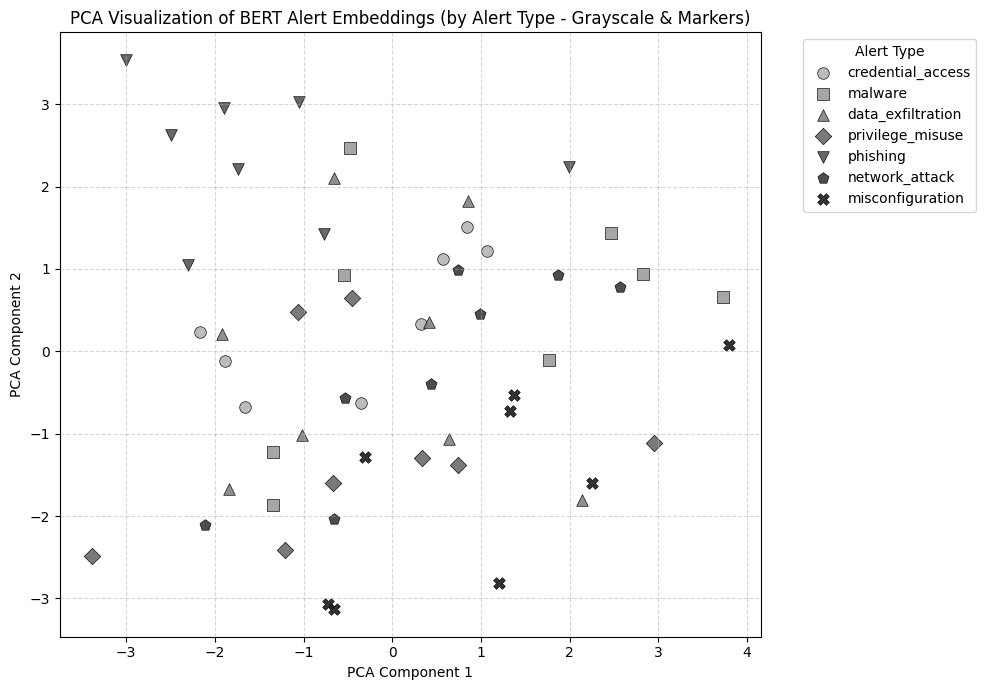

In [11]:
import matplotlib.pyplot as plt
import numpy as np

# Distinct markers for each alert type
markers = [
    "o", # Circle
    "s", # Square
    "^", # Triangle Up
    "D", # Diamond
    "v", # Triangle Down
    "p", # Pentagon
    "X", # Bold X
    "*"  # Star
]

# Generate a list of shades from the 'Greys' colormap
unique_alerts = df["alert_type"].unique()
num_categories = len(unique_alerts)
greys_palette = plt.cm.Greys(np.linspace(0.4, 0.9, num_categories))

plt.figure(figsize=(10, 7))

# Loop over each unique alert type to plot them with custom labels, grayscale shades, and markers
for i, alert_type in enumerate(unique_alerts):
    subset = df[df["alert_type"] == alert_type]
    color = greys_palette[i]
    marker = markers[i % len(markers)]

    plt.scatter(
        subset["pca_1"],
        subset["pca_2"],
        label=alert_type,
        color=color,
        marker=marker,
        alpha=0.9,
        s=70,
        edgecolors="black",
        linewidths=0.5
    )

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("PCA Visualization of BERT Alert Embeddings (by Alert Type - Grayscale & Markers)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title="Alert Type")
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [12]:
# Calculate the exact variance explained and discarded
# I added this block because I asked gemini for help and didn't understand where the lost variance came from.

explained_variance = pca.explained_variance_ratio_
total_explained = np.sum(explained_variance) * 100
discarded_variance = (1 - np.sum(explained_variance)) * 100

print(f"Explained variance ratio per component: {explained_variance}")
print(f"Total explained variance (PC1 + PC2): {total_explained:.1f}%")
print(f"Discarded (lost) variance: {discarded_variance:.1f}%")

Explained variance ratio per component: [0.11042616 0.10303818]
Total explained variance (PC1 + PC2): 21.3%
Discarded (lost) variance: 78.7%


### Question 3

Look at your PCA plots and answer:

1. **Do alerts with similar severity scores appear close together?**

   Kind of?  The first PCA plot has gradients of severity scores. I changed the color scheme to grey scale to make sure I wasn't missing something with the colors. I don't think 2D representation captures enough detail. There are some identifiable trends, but some are ambiguous.

2. **Do alerts of the same alert type appear close together?**

   Yes. The second PCA plot has clusterings of the same blocks. Phishing is pretty clearly clustered. Credential access is clustered.

3. **What information is lost when we reduce BERT embeddings from hundreds of dimensions to only two PCA components?**

   Reducing 768 dimensions to just 2 dimensions discards about **78.6%** of the total variance (since the two components only explain ~21.3% of the variance combined). This dimensionality reduction collapses complex semantic relationships, subtle context, and specific text nuances into a simple 2D representation, resulting in overlapping clusters and loss of detail necessary for fine-grained prediction. (gemini, said so, see previous block for the calculations)
   

## 7. Prepare data for regression


We will compare three feature sets:

1. **Structured features only**
2. **BERT embeddings only**
3. **Structured features + BERT embeddings**

The target variable is `severity_score`.


In [13]:

structured_features = [
    "failed_login_count",
    "unusual_geo",
    "privilege_escalation",
    "data_exfiltration",
    "malware_detected",
    "asset_criticality"
]

X_structured = df[structured_features].values
X_bert = bert_embeddings
y = df["severity_score"].values

# Scale structured features before combining them with BERT embeddings.
scaler = StandardScaler()
X_structured_scaled = scaler.fit_transform(X_structured)

X_combined = np.hstack([X_structured_scaled, X_bert])

print("Structured feature shape:", X_structured_scaled.shape)
print("BERT feature shape:", X_bert.shape)
print("Combined feature shape:", X_combined.shape)


Structured feature shape: (56, 6)
BERT feature shape: (56, 768)
Combined feature shape: (56, 774)


In [14]:

# Split all three feature sets using the same train/test split.

X_train_struct, X_test_struct, y_train, y_test = train_test_split(
    X_structured_scaled, y, test_size=0.25, random_state=42
)

X_train_bert, X_test_bert, _, _ = train_test_split(
    X_bert, y, test_size=0.25, random_state=42
)

X_train_combined, X_test_combined, _, _ = train_test_split(
    X_combined, y, test_size=0.25, random_state=42
)

print("Training observations:", len(y_train))
print("Testing observations:", len(y_test))


Training observations: 42
Testing observations: 14


## 8. Define an evaluation function

In [15]:

def evaluate_regression_model(model, X_train, X_test, y_train, y_test, model_name):
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    return {
        "model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }, predictions


## 9. Train and evaluate baseline and regression models

In [16]:

results = []

# Baseline model: always predicts the average severity score in the training data.
baseline = DummyRegressor(strategy="mean")
baseline_result, baseline_predictions = evaluate_regression_model(
    baseline,
    X_train_struct,
    X_test_struct,
    y_train,
    y_test,
    "Baseline Mean Predictor"
)
results.append(baseline_result)

# Ridge Regression with structured features only.
ridge_struct = Ridge(alpha=1.0)
ridge_struct_result, ridge_struct_predictions = evaluate_regression_model(
    ridge_struct,
    X_train_struct,
    X_test_struct,
    y_train,
    y_test,
    "Ridge Regression: Structured Features Only"
)
results.append(ridge_struct_result)

# Ridge Regression with BERT embeddings only.
ridge_bert = Ridge(alpha=10.0)
ridge_bert_result, ridge_bert_predictions = evaluate_regression_model(
    ridge_bert,
    X_train_bert,
    X_test_bert,
    y_train,
    y_test,
    "Ridge Regression: BERT Embeddings Only"
)
results.append(ridge_bert_result)

# Ridge Regression with structured features + BERT embeddings.
ridge_combined = Ridge(alpha=10.0)
ridge_combined_result, ridge_combined_predictions = evaluate_regression_model(
    ridge_combined,
    X_train_combined,
    X_test_combined,
    y_train,
    y_test,
    "Ridge Regression: Structured + BERT"
)
results.append(ridge_combined_result)

results_df = pd.DataFrame(results)
results_df


,model,MAE,RMSE,R2
0,Baseline Mean Predictor,22.367347,23.432068,-0.164614
1,Ridge Regression: Structured Features Only,5.954811,7.455803,0.882090
2,Ridge Regression: BERT Embeddings Only,18.717869,21.047988,0.060316
3,Ridge Regression: Structured + BERT,7.802425,8.829693,0.834632


In [17]:
# TODO 3:
# Add a Random Forest Regressor using the combined feature set.
# Use random_state=42.
# Add its results to results_df.
# Hint: Use RandomForestRegressor(n_estimators=200, random_state=42)

# Your code here
rf_combined = RandomForestRegressor(n_estimators=200, random_state=42)
rf_combined_result, rf_combined_predictions = evaluate_regression_model(
    rf_combined,
    X_train_combined,
    X_test_combined,
    y_train,
    y_test,
    "Random Forest: Structured + BERT"
)

results.append(rf_combined_result)
results_df = pd.DataFrame(results)
display(results_df)

,model,MAE,RMSE,R2
0,Baseline Mean Predictor,22.367347,23.432068,-0.164614
1,Ridge Regression: Structured Features Only,5.954811,7.455803,0.882090
2,Ridge Regression: BERT Embeddings Only,18.717869,21.047988,0.060316
3,Ridge Regression: Structured + BERT,7.802425,8.829693,0.834632
4,Random Forest: Structured + BERT,9.192500,10.179458,0.780209


### Question 4

Based on the regression results:

1. **Which model has the lowest MAE?**
   Ridge Regression: Structured Features Only has the lowest MAE - 5.95

2. **Which model has the lowest RMSE?**
   Ridge Regression: Structured Features Only has the lowest RMSE - 7.46

3. **Which model has the highest R²?**
   Ridge Regression: Structured Features Only** has the highest $R^2$ - 0.88

4. **Did BERT embeddings improve performance compared with structured features only?**
   No. The BERT-only model performed poorly ($R^2$ of **0.06**, MAE of **18.72**), which is only slightly better than the baseline mean predictor ($R^2$ of **-0.16**).

5. **Did combining structured features and BERT embeddings improve performance?**
   No. Both combined models performed worse than the structured-only model. Ridge Regression with structured + BERT features had an MAE of **7.80** ($R^2$ of **0.83**), and the Random Forest Regressor with combined features had an MAE of **9.19** ($R^2$ of **0.78**). Adding the high-dimensional BERT embeddings (768 dimensions) likely introduced noise and caused overfitting on this very small dataset (56 samples).

## 10. Visualize actual vs. predicted severity

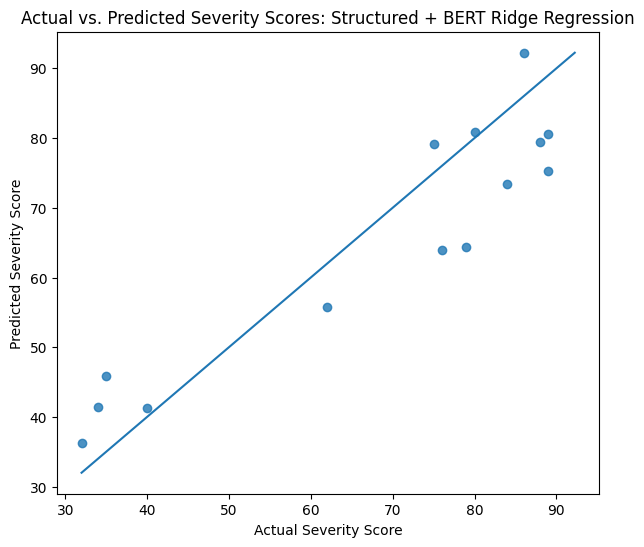

In [18]:

# Use the combined Ridge Regression model predictions.

plt.figure(figsize=(7, 6))
plt.scatter(y_test, ridge_combined_predictions, alpha=0.8)

plt.xlabel("Actual Severity Score")
plt.ylabel("Predicted Severity Score")
plt.title("Actual vs. Predicted Severity Scores: Structured + BERT Ridge Regression")

# Reference line for perfect predictions.
min_value = min(y_test.min(), ridge_combined_predictions.min())
max_value = max(y_test.max(), ridge_combined_predictions.max())
plt.plot([min_value, max_value], [min_value, max_value])

plt.show()


In [19]:

# Create a dataframe of test predictions for error analysis.

error_df = pd.DataFrame({
    "actual_severity": y_test,
    "predicted_severity": ridge_combined_predictions
})

error_df["absolute_error"] = np.abs(error_df["actual_severity"] - error_df["predicted_severity"])

error_df.sort_values("absolute_error", ascending=False).head()


,actual_severity,predicted_severity,absolute_error
2,79,64.347836,14.652164
8,89,75.251703,13.748297
6,76,63.953213,12.046787
0,35,45.857180,10.857180
7,84,73.410554,10.589446


In [20]:
# TODO 4:
# Improve the error analysis dataframe by adding the original alert text and alert type.
# Hint: Use the test indices from train_test_split or create a split that preserves indices.

# Get the indices of the test set by splitting the DataFrame's index
_, test_indices = train_test_split(
    df.index, test_size=0.25, random_state=42
)

# Construct the improved error analysis DataFrame
error_df_improved = pd.DataFrame({
    "alert_text": df.loc[test_indices, "alert_text"].values,
    "alert_type": df.loc[test_indices, "alert_type"].values,
    "actual_severity": y_test,
    "predicted_severity": ridge_combined_predictions
})

error_df_improved["absolute_error"] = np.abs(error_df_improved["actual_severity"] - error_df_improved["predicted_severity"])

# Display the top 5 largest errors
display(error_df_improved.sort_values("absolute_error", ascending=False).head())

,alert_text,alert_type,actual_severity,predicted_severity,absolute_error
2,Employee clicked phishing link and entered cre...,phishing,79,64.347836,14.652164
8,Suspicious lateral movement observed between i...,network_attack,89,75.251703,13.748297
6,Credential harvesting page detected after phis...,phishing,76,63.953213,12.046787
0,Repeated failed login attempts detected for em...,credential_access,35,45.857180,10.857180
7,Administrative role assigned to user outside n...,privilege_misuse,84,73.410554,10.589446


### Question 5

Based on the improved error analysis results:

1. **Which alerts were hardest for the model to predict?**
   The alerts with the largest absolute errors were:
   - **Employee clicked phishing link and entered credentials...** (`alert_type`: `phishing`): actual severity 79, predicted 64.35 (underestimated by ~14.6).
   - **Unusual upload of customer records to personal cloud...** (`alert_type`: `data_exfiltration`): actual severity 89, predicted 75.25 (underestimated by ~13.7).
   - **Credential harvesting page detected...** (`alert_type`: `phishing`): actual severity 76, predicted 63.95 (underestimated by ~12.0).
   - **Repeated failed login attempts...** (`alert_type`: `credential_access`): actual severity 35, predicted 45.86 (overestimated by ~10.9).
   - **Administrative role assigned to user...** (`alert_type`: `privilege_misuse`): actual severity 84, predicted 73.41 (underestimated by ~10.6).

2. **Were high-severity alerts or low-severity alerts more difficult?**
   **High-severity alerts** were more difficult. Out of the top 5 largest errors, 4 of them were high-severity alerts (actual scores of 76, 79, 84, and 89) where the model consistently underestimated the severity of the threat.

3. **What could happen if a cybersecurity triage model underestimates a severe alert?**
   If a severe alert is underestimated, it will receive a lower priority queue ranking. Consequently, security analysts may not investigate it in a timely manner. This delay gives attackers more time to move laterally, exfiltrate sensitive data, or complete ransomware actions, leading to a catastrophic security breach.

4. **What could happen if it overestimates many low-risk alerts?**
   Overestimating low-risk alerts leads to **alert fatigue**. Analysts' queues will be flooded with false alarms and low-priority tasks flagged as urgent. This wastes valuable cybersecurity resources, reduces morale, and increases the likelihood that analysts will burn out or miss real, critical threats buried in the noise.

## 11. Optional extension: classify alerts into risk levels


Regression predicts a numeric severity score. In some business settings, security teams may prefer categories such as:

- Low risk
- Medium risk
- High risk

Optional: Create a new column called `risk_level` based on `severity_score`, then train a classification model.


In [21]:
# OPTIONAL TODO:
# Create a risk_level column.
# Example:
# 0-39 = Low
# 40-69 = Medium
# 70-100 = High
#
# Then train and evaluate a classifier using BERT embeddings or combined features.

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# 1. Create a function to bin severity_score into risk levels
def get_risk_level(score):
    if score <= 39:
        return "Low"
    elif score <= 69:
        return "Medium"
    else:
        return "High"

df["risk_level"] = df["severity_score"].apply(get_risk_level)

# 2. Extract targets
y_class = df["risk_level"].values

# 3. Split the data using the same split
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_combined, y_class, test_size=0.25, random_state=42
)

# 4. Train a Random Forest Classifier
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train_c, y_train_c)
y_pred_c = clf.predict(X_test_c)

# 5. Evaluate the classifier
accuracy = accuracy_score(y_test_c, y_pred_c)
print(f"Classification Accuracy: {accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_test_c, y_pred_c))

Classification Accuracy: 0.5714

Classification Report:
              precision    recall  f1-score   support

        High       0.78      0.78      0.78         9
         Low       1.00      0.33      0.50         3
      Medium       0.00      0.00      0.00         2

    accuracy                           0.57        14
   macro avg       0.59      0.37      0.43        14
weighted avg       0.71      0.57      0.61        14




## 12. Responsible AI reflection

Answer these questions in complete sentences.

1. Why should cybersecurity analysts not rely only on an AI-generated severity score?

    Novel cybersecurity risks are under represented in existing historical cybersecurity analysis.

2. What types of alerts might be unfairly underestimated by a model trained on historical data?

    **Novel cybersecurity risks are under represented in existing historical cybersecurity analysis.**

3. What information should be shown to a human analyst so they can understand why an alert received a high or low score?
An analyst needs more context, like privilege,criticality,  escalation.

4. How could an organization monitor this model after deployment?
Performance metrics that compare predicted risk and severity scores against actually outcomes.

5. What are the advantages and disadvantages of using BERT embeddings instead of simpler methods such as TF-IDF?

The advantage is that BERT can captures deep contextual relationships.
The disadvantage is that computer resource intensive. It isn't well suited to smaller datasets.


## Grading rubric: 100 points

| Section | Points |
|---|---:|
| Dataset inspection and interpretation | 10 |
| Correct creation and explanation of BERT embeddings | 15 |
| PCA visualization and interpretation | 15 |
| Regression modeling and baseline comparison | 20 |
| Model evaluation using MAE, RMSE, and R² | 15 |
| Error analysis | 10 |
| Responsible AI reflection | 10 |
| Notebook runs successfully and is clearly organized | 5 |
